In [ ]:
import pandas as pd
df= pd.read_csv('/content/beers.csv')

In [ ]:
df.head()

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
0,0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


In [ ]:
df.tail()

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
2405,2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0
2406,2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0
2407,2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0
2408,2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0
2409,2409,0.052,NaN,84,Rail Yard Ale (2009),American Amber / Red Ale,424,12.0


In [ ]:
df.describe()

,Unnamed: 0,abv,ibu,id,brewery_id,ounces
count,2410.000000,2348.000000,1405.000000,2410.000000,2410.000000,2410.000000
mean,1204.500000,0.059773,42.713167,1431.113278,231.749793,13.592241
std,695.851397,0.013542,25.954066,752.459975,157.685604,2.352204
min,0.000000,0.001000,4.000000,1.000000,0.000000,8.400000
25%,602.250000,0.050000,21.000000,808.250000,93.000000,12.000000
50%,1204.500000,0.056000,35.000000,1453.500000,205.000000,12.000000
75%,1806.750000,0.067000,64.000000,2075.750000,366.000000,16.000000
max,2409.000000,0.128000,138.000000,2692.000000,557.000000,32.000000


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
abv,62
ibu,1005
id,0
name,0
style,5
brewery_id,0
ounces,0


In [ ]:
df.shape

(2410, 8)

In [ ]:
df.dtypes

,0
Unnamed: 0,int64
abv,float64
ibu,float64
id,int64
name,object
style,object
brewery_id,int64
ounces,float64


In [ ]:
df["ounces"].unique()

array([12. ,  8.4, 16. , 24. , 19.2, 32. , 16.9])

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,2410.0,1204.500000,695.851397,0.000,602.25,1204.500,1806.750,2409.000
abv,2348.0,0.059773,0.013542,0.001,0.05,0.056,0.067,0.128
ibu,1405.0,42.713167,25.954066,4.000,21.00,35.000,64.000,138.000
id,2410.0,1431.113278,752.459975,1.000,808.25,1453.500,2075.750,2692.000
brewery_id,2410.0,231.749793,157.685604,0.000,93.00,205.000,366.000,557.000
ounces,2410.0,13.592241,2.352204,8.400,12.00,12.000,16.000,32.000


In [ ]:
Q1 = df['ounces'].quantile(0.25)
Q3 = df['ounces'].quantile(0.75)
IQR = Q3 - Q1

print(f"Q1 (25th percentile): {Q1}")
print(f"Q3 (75th percentile): {Q3}")
print(f"IQR (Interquartile Range): {IQR}")

Q1 (25th percentile): 12.0
Q3 (75th percentile): 16.0
IQR (Interquartile Range): 4.0


In [ ]:
lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR

In [ ]:
outliers = df[(df['ounces'] < lb) | (df['ounces'] > ub)]
outliers

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
477,477,0.078,NaN,2606,Mr. Tea,Fruit / Vegetable Beer,24,24.0
581,581,0.070,NaN,2057,Stickin' In My Rye,Rye Beer,236,24.0
957,957,0.045,15.0,404,Black Star Double Hopped Golden Lager (24 oz.),American Pale Lager,543,24.0
1181,1181,0.046,18.0,1274,Longboard Island Lager,American Amber / Red Lager,439,24.0
1341,1341,0.083,NaN,2535,Vinyl Frontier,American Double / Imperial IPA,65,24.0
1342,1342,0.080,NaN,2534,Disco Superfly,American IPA,65,24.0
1343,1343,0.075,NaN,2533,Misty Mountain Hop,American IPA,65,24.0
1344,1344,0.075,NaN,2532,One-Hit Wonderful,Belgian IPA,65,24.0
1345,1345,0.065,NaN,2531,En Parfaite Harmonie,Saison / Farmhouse Ale,65,24.0
1346,1346,0.043,8.0,2530,Daft Funk,Berliner Weissbier,65,24.0


In [ ]:
# To count the number of outliers:
print(f"Number of outliers: {len(outliers)}")

# To get the sum of numeric columns only:
outliers.sum(numeric_only=True)

Number of outliers: 27


,0
Unnamed: 0,38452.000
abv,1.687
ibu,379.000
id,50572.000
brewery_id,5203.000
ounces,688.000


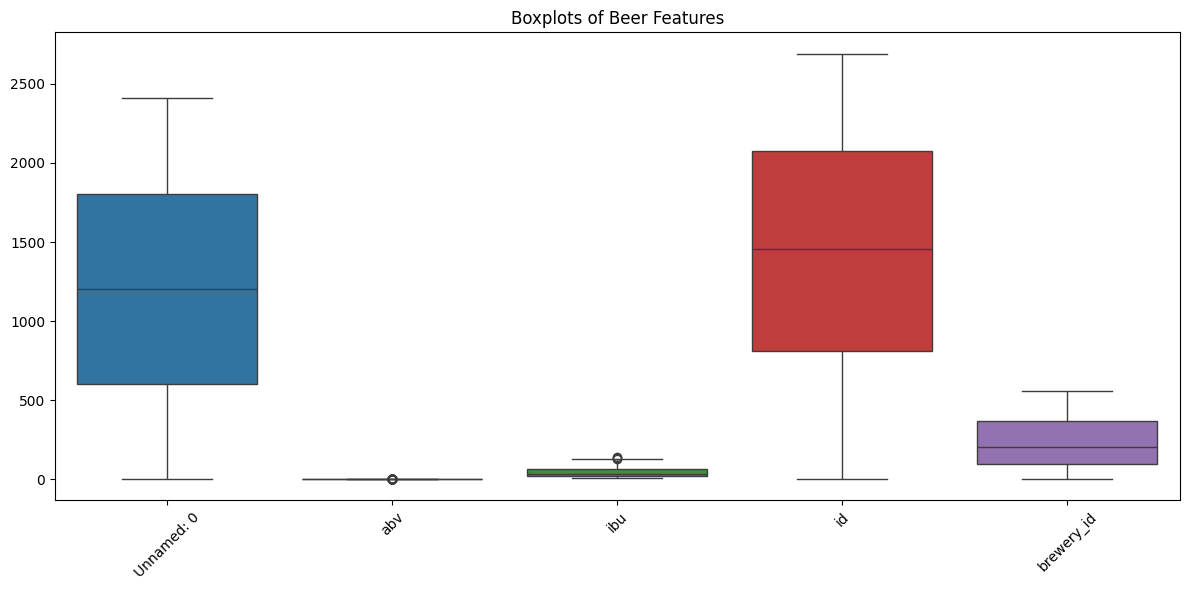

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the dataframe is loaded to prevent NameError
df = pd.read_csv('/content/beers.csv')

plt.figure(figsize=(12, 6))

sns.boxplot(data=df.drop(columns=["ounces"]))

plt.xticks(rotation=45)
plt.title("Boxplots of Beer Features")
plt.tight_layout()
plt.show()

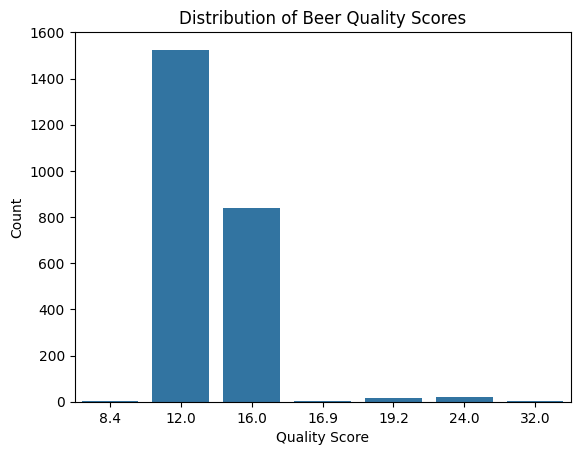

In [ ]:
sns.countplot(data=df, x="ounces")
plt.title("Distribution of Beer Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Count")
plt.show()

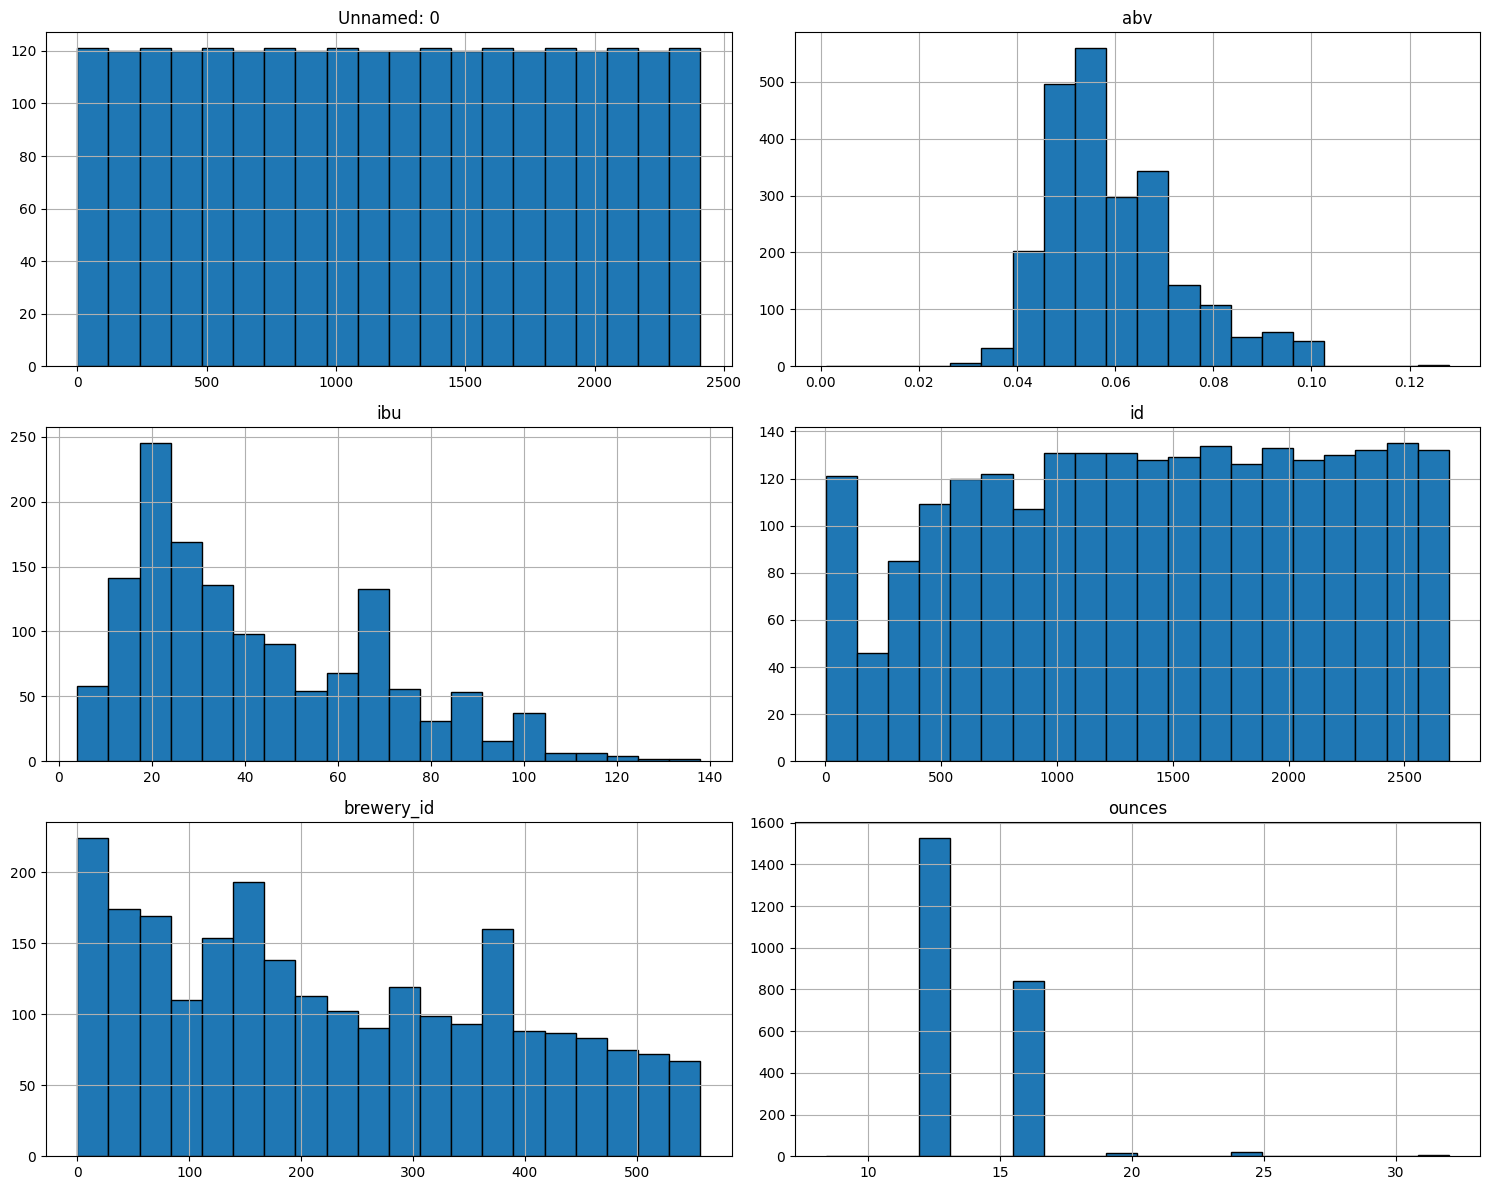

In [ ]:
df.hist(figsize=(15, 12), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

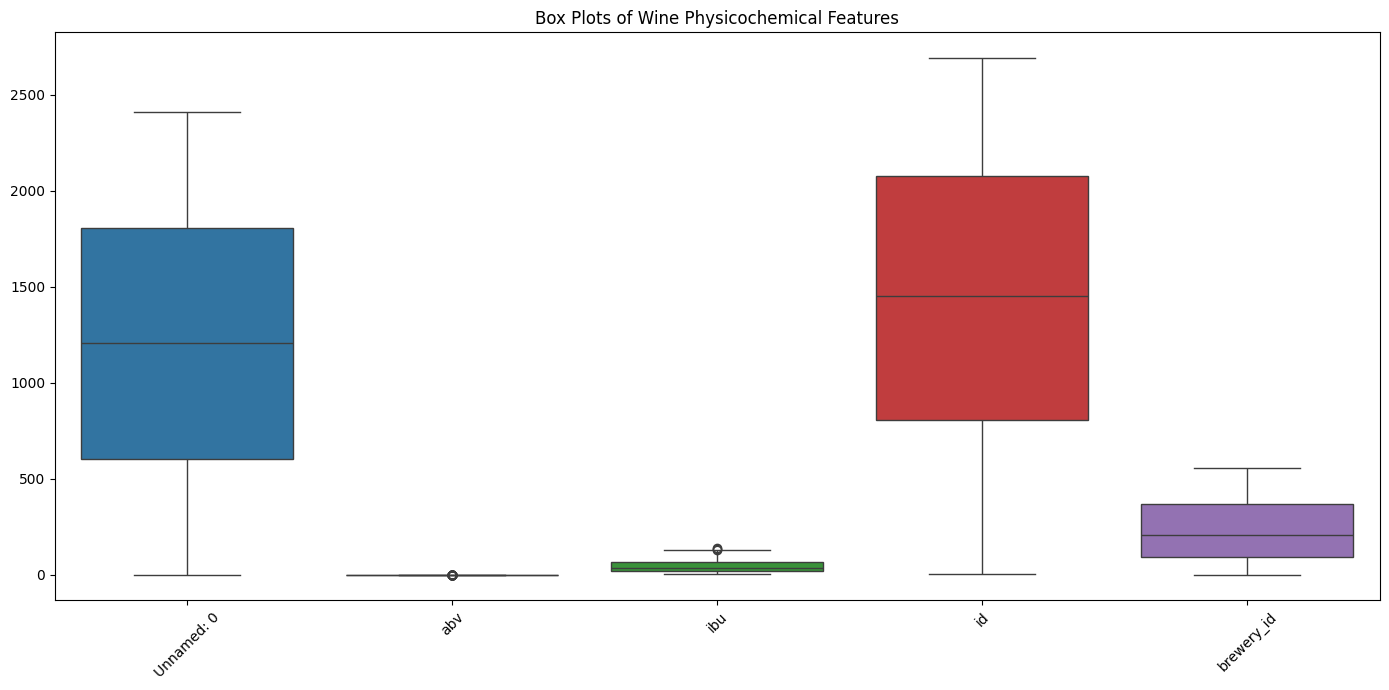

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df.drop(columns=["ounces"]))

plt.xticks(rotation=45)
plt.title("Box Plots of Wine Physicochemical Features")
plt.tight_layout()
plt.show()

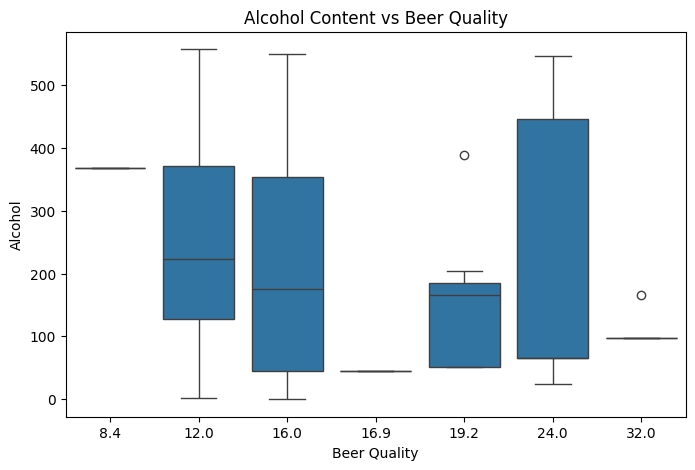

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="ounces", y="brewery_id")

plt.title("Alcohol Content vs Beer Quality")
plt.xlabel("Beer Quality")
plt.ylabel("Alcohol")
plt.show()

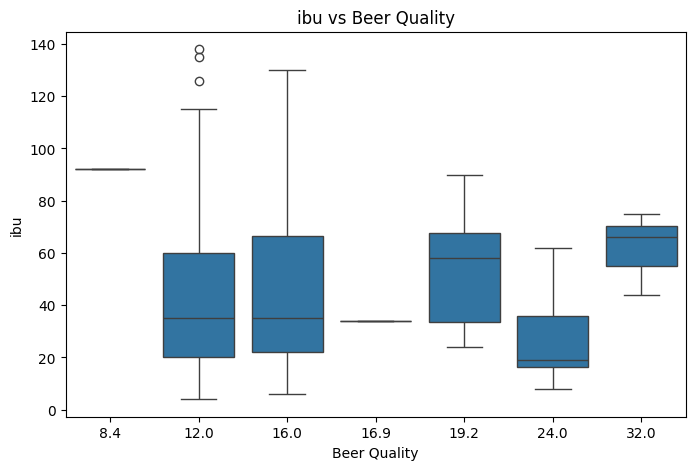

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="ounces", y="ibu")

plt.title("ibu vs Beer Quality")
plt.xlabel("Beer Quality")
plt.ylabel("ibu")
plt.show()

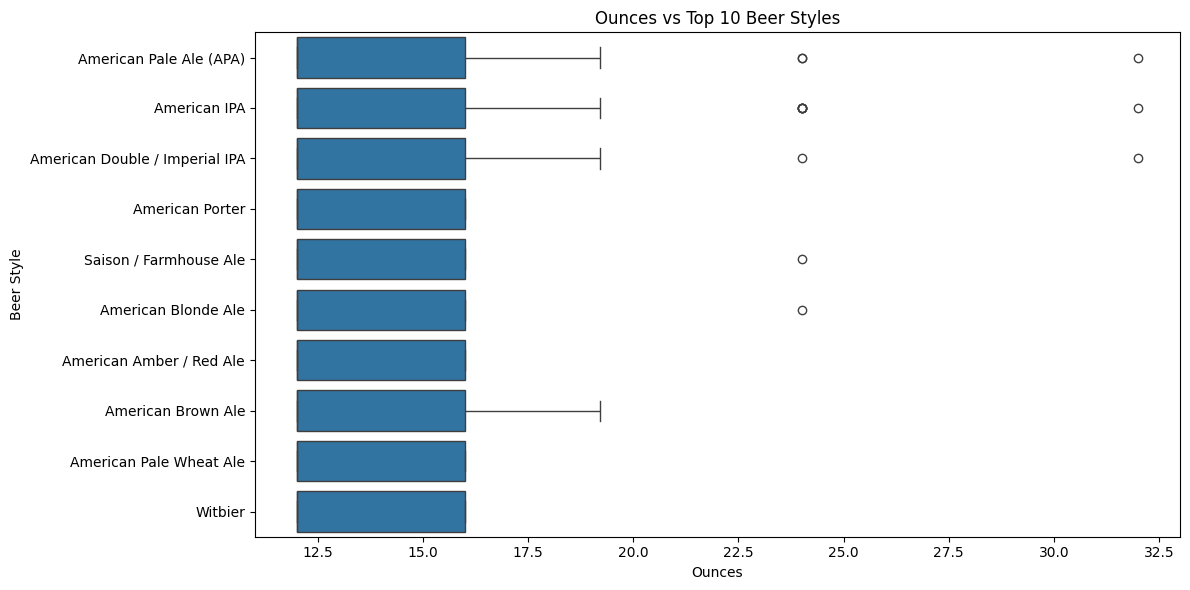

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for the top 10 most frequent beer styles to keep the plot readable
top_styles = df['style'].value_counts().nlargest(10).index
df_filtered = df[df['style'].isin(top_styles)]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df_filtered, x="ounces", y="style")

plt.title("Ounces vs Top 10 Beer Styles")
plt.xlabel("Ounces")
plt.ylabel("Beer Style")
plt.tight_layout()
plt.show()

In [ ]:
correlations = (
    df.corr(numeric_only=True)["ounces"]
    .drop("ounces")
    .sort_values(ascending=False)
)

print(correlations)

abv           0.172529
id            0.100843
ibu           0.054691
Unnamed: 0    0.037981
brewery_id   -0.133762
Name: ounces, dtype: float64


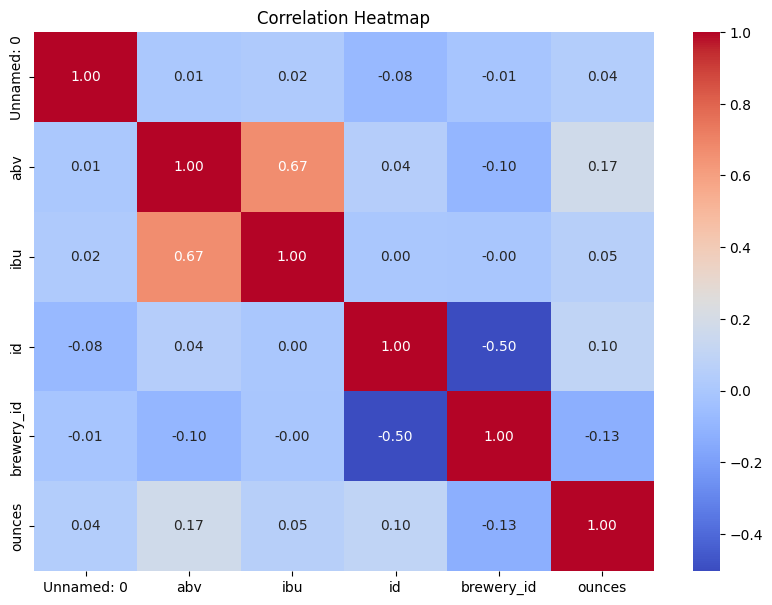

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

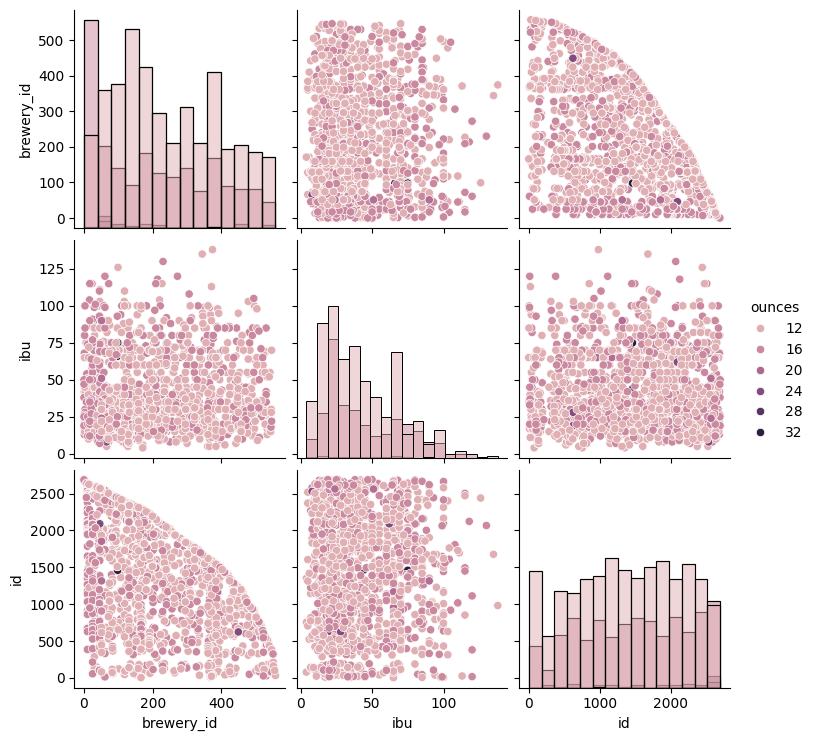

In [ ]:
selected = [
    "brewery_id",
    "ibu",
    "id",
    "ounces"
]

sns.pairplot(
    df[selected],
    hue="ounces",
    diag_kind="hist"
)

plt.show()

In [ ]:
df.groupby("ounces")[
    ["brewery_id", "abv", "ibu", "id"]
].median().round(3)

,brewery_id,abv,ibu,id
ounces,,,,
8.4,368.0,0.099,92.0,1036.0
12.0,223.0,0.055,35.0,1397.0
16.0,175.0,0.060,35.0,1515.0
16.9,45.0,0.085,34.0,2575.0
19.2,166.0,0.075,58.0,2179.0
24.0,65.0,0.065,19.0,2444.5
32.0,98.0,0.059,66.0,1796.0


In [ ]:
Q1 = df.quantile(0.25, numeric_only=True)
Q3 = df.quantile(0.75, numeric_only=True)
IQR = Q3 - Q1
lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR

outliers = df[(df["ounces"] < lb["ounces"]) | (df["ounces"] > ub["ounces"])]
outliers.sum(numeric_only=True)

,0
Unnamed: 0,38452.000
abv,1.687
ibu,379.000
id,50572.000
brewery_id,5203.000
ounces,688.000


In [ ]:
len(outliers) / len(df) * 100

1.120331950207469

In [ ]:
outliers

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
477,477,0.078,NaN,2606,Mr. Tea,Fruit / Vegetable Beer,24,24.0
581,581,0.070,NaN,2057,Stickin' In My Rye,Rye Beer,236,24.0
957,957,0.045,15.0,404,Black Star Double Hopped Golden Lager (24 oz.),American Pale Lager,543,24.0
1181,1181,0.046,18.0,1274,Longboard Island Lager,American Amber / Red Lager,439,24.0
1341,1341,0.083,NaN,2535,Vinyl Frontier,American Double / Imperial IPA,65,24.0
1342,1342,0.080,NaN,2534,Disco Superfly,American IPA,65,24.0
1343,1343,0.075,NaN,2533,Misty Mountain Hop,American IPA,65,24.0
1344,1344,0.075,NaN,2532,One-Hit Wonderful,Belgian IPA,65,24.0
1345,1345,0.065,NaN,2531,En Parfaite Harmonie,Saison / Farmhouse Ale,65,24.0
1346,1346,0.043,8.0,2530,Daft Funk,Berliner Weissbier,65,24.0


In [ ]:
df["abv"].head()

,abv
0,0.050
1,0.066
2,0.071
3,0.090
4,0.075


In [ ]:
df.skew(numeric_only=True)

,0
Unnamed: 0,0.000000
abv,0.958477
ibu,0.792521
id,-0.121246
brewery_id,0.307974
ounces,2.046687


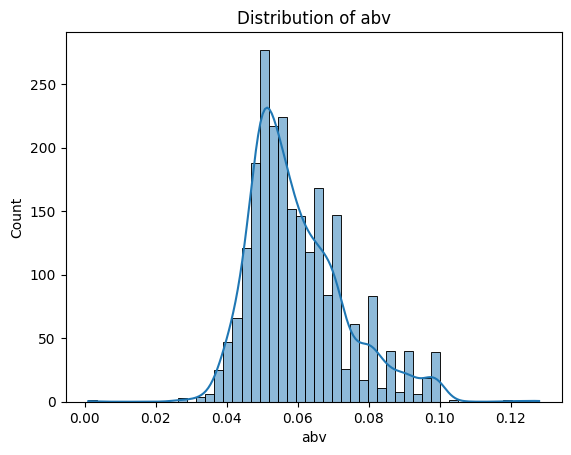

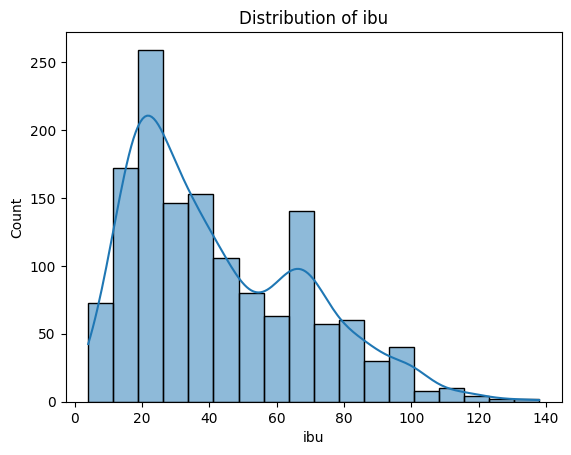

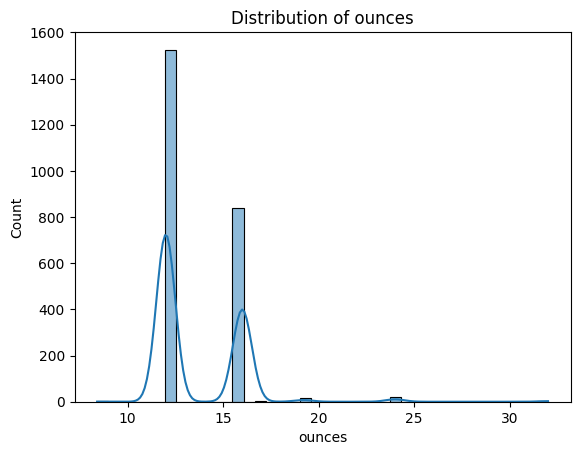

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["abv", "ibu", "ounces"]

for col in cols:
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [ ]:
Q1 = df.quantile(0.25, numeric_only=True)
Q3 = df.quantile(0.75, numeric_only=True)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_capped = df.copy()

cols = df.select_dtypes(include="number").columns.drop("ounces")

df_capped[cols] = df_capped[cols].clip(
    lower=lower[cols],
    upper=upper[cols],
    axis=1
)

In [ ]:
print("Original shape:", df.shape)
print("Capped shape:", df_capped.shape)

print("\nOriginal maximum:")
print(df[cols].max())

print("\nCapped maximum:")
print(df_capped[cols].max())

Original shape: (2410, 8)
Capped shape: (2410, 8)

Original maximum:
Unnamed: 0    2409.000
abv              0.128
ibu            138.000
id            2692.000
brewery_id     557.000
dtype: float64

Capped maximum:
Unnamed: 0    2409.0000
abv              0.0925
ibu            128.5000
id            2692.0000
brewery_id     557.0000
dtype: float64


In [ ]:
import pandas as pd
df= pd.read_csv('/content/beers.csv')

In [ ]:
from sklearn.model_selection import train_test_split
X=df.drop(["ounces"],axis=1)
y=df["ounces"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [ ]:
Q1 = X_train.quantile(0.25, numeric_only=True)
Q3 = X_train.quantile(0.75, numeric_only=True)

IQR = Q3 - Q1

lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR

In [ ]:
X_train_capped = X_train.clip(lower=lb, upper=ub, axis=1)
X_test_capped = X_test.clip(lower=lb, upper=ub, axis=1)


In [ ]:
print("Original training shape:", X_train.shape)
print("Capped training shape:", X_train_capped.shape)

print("Original test shape:", X_test.shape)
print("Capped test shape:", X_test_capped.shape)

Original training shape: (1928, 7)
Capped training shape: (1928, 7)
Original test shape: (482, 7)
Capped test shape: (482, 7)


In [ ]:
print("Skewness before capping:")
print(X_train.skew(numeric_only=True).sort_values(ascending=False))

print("\nSkewness after capping:")
print(X_train_capped.skew(numeric_only=True).sort_values(ascending=False))

Skewness before capping:
abv           0.912704
ibu           0.805004
brewery_id    0.287911
Unnamed: 0    0.001172
id           -0.105727
dtype: float64

Skewness after capping:
ibu           0.790724
abv           0.748589
brewery_id    0.287911
Unnamed: 0    0.001172
id           -0.105727
dtype: float64


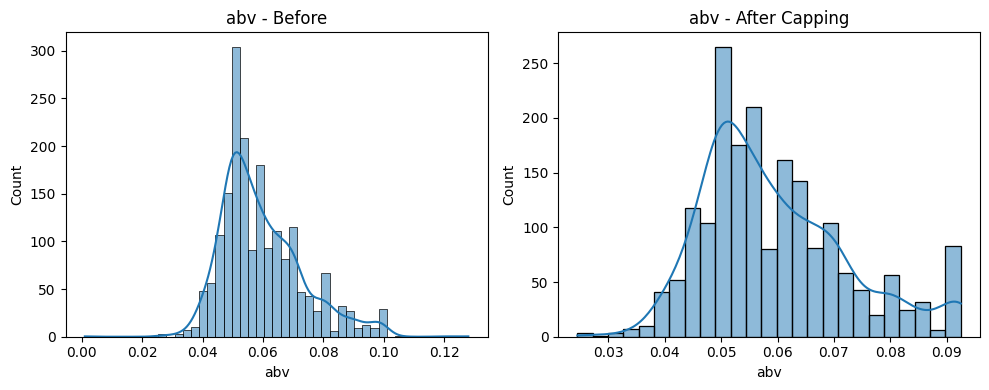

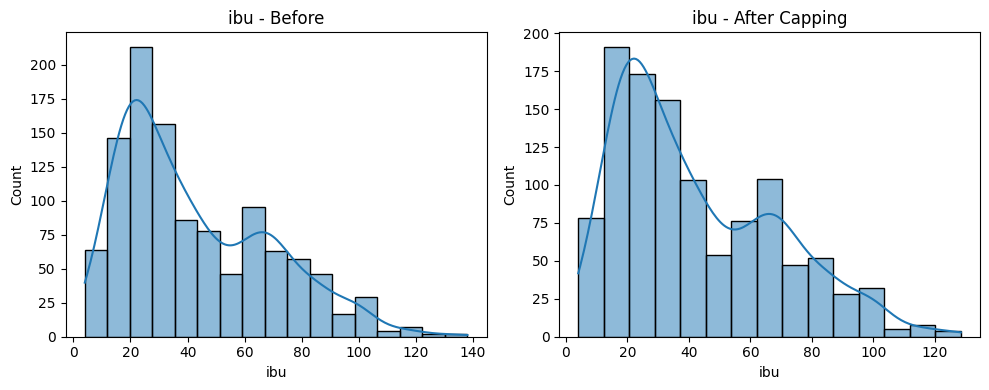

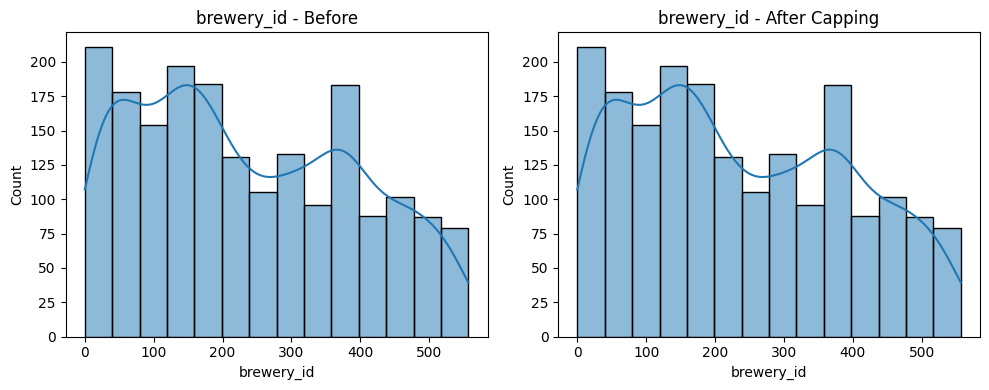

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["abv", "ibu", "brewery_id"]

for col in cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.histplot(X_train[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"{col} - Before")

    sns.histplot(X_train_capped[col].dropna(), kde=True, ax=axes[1])
    axes[1].set_title(f"{col} - After Capping")

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np

In [ ]:
X_test_sqrt= X_test_capped.copy()


In [ ]:
X_test_sqrt[cols]=np.sqrt(X_test_sqrt[cols])

In [ ]:
X_train_sqrt = X_train_capped.copy()


In [ ]:
X_train_sqrt[cols]=np.sqrt(X_train_sqrt[cols])



In [ ]:
X_train_sqrt.skew()

,0
Unnamed: 0,0.001172
abv,0.493915
ibu,0.297094
id,-0.105727
name,NaN
style,NaN
brewery_id,-0.32652


In [ ]:
X_test_sqrt.skew()


,0
Unnamed: 0,-0.004984
abv,0.679657
ibu,0.265213
id,-0.178411
name,NaN
style,NaN
brewery_id,-0.184815


In [ ]:
Q1 = X_train_sqrt.quantile(0.25, numeric_only=True)
Q3 = X_train_sqrt.quantile(0.75, numeric_only=True)

IQR = Q3 - Q1

lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR


outliers1 = (X_train_sqrt[ub.index] > ub)

In [ ]:
outliers1.sum()

,0
Unnamed: 0,0
abv,0
ibu,0
id,0
brewery_id,0


In [ ]:
Q1 = X_test_sqrt.quantile(0.25)
Q3 = X_test_sqrt.quantile(0.75)

IQR = Q3 - Q1

lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR
outliers2=(X_train_sqrt[ub.index] > ub)

In [ ]:
outliers2.sum()

,0
Unnamed: 0,0
abv,0
ibu,0
id,0
name,0
style,0
brewery_id,0


In [ ]:
features_recip = ["abv", "ibu"]

X_train_recip = X_train_sqrt.copy()
X_test_recip = X_test_sqrt.copy()

X_train_recip[features_recip] = 1 / X_train_recip[features_recip]
X_test_recip[features_recip] = 1 / X_test_recip[features_recip]

print("Before reciprocal — training:")
print(X_train_sqrt[features_recip].skew())

print("\nAfter reciprocal — training:")
print(X_train_recip[features_recip].skew())

Before reciprocal — training:
abv    0.493915
ibu    0.297094
dtype: float64

After reciprocal — training:
abv    0.110319
ibu    1.253502
dtype: float64


In [ ]:
Q1 = X_test_recip.quantile(0.25, numeric_only=True)
Q3 = X_test_recip.quantile(0.75, numeric_only=True)

IQR = Q3 - Q1

lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR

outliers3 = (X_test_recip[ub.index] > ub)

In [ ]:
outliers3.sum()

,0
Unnamed: 0,0
abv,0
ibu,2
id,0
brewery_id,0


In [ ]:
X_train_final = X_train_sqrt.copy()
X_test_final = X_test_sqrt.copy()


In [ ]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
X_train_robust=scaler.fit_transform(X_train_final)
X_test_robust=scaler.transform(X_test_final)

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1243: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1437: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


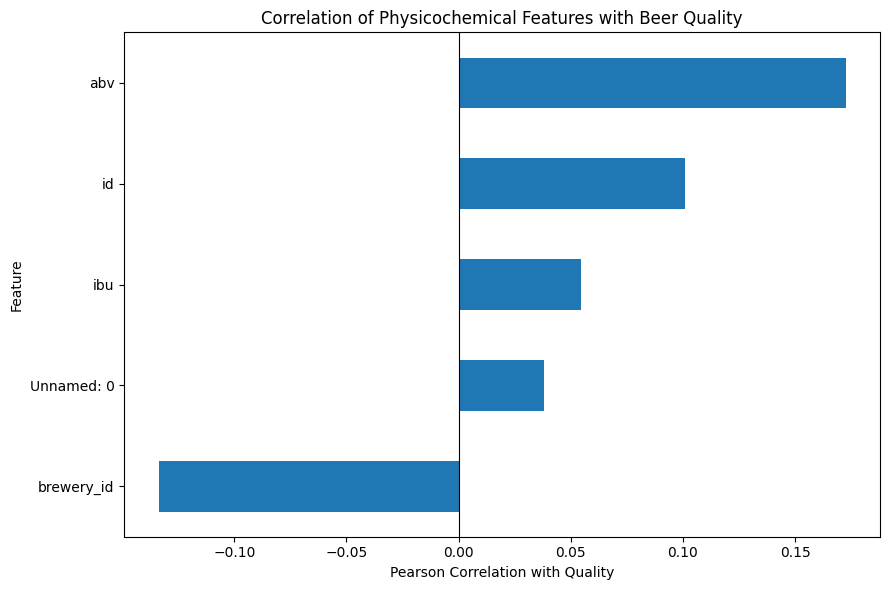

abv           0.173
id            0.101
ibu           0.055
Unnamed: 0    0.038
brewery_id   -0.134
Name: ounces, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

quality_corr = (
    df.corr(numeric_only=True)["ounces"]
    .drop("ounces")
    .sort_values()
)

plt.figure(figsize=(9, 6))
quality_corr.plot(kind="barh")
plt.title("Correlation of Physicochemical Features with Beer Quality")
plt.xlabel("Pearson Correlation with Quality")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print(quality_corr.sort_values(ascending=False).round(3))

In [ ]:
X = df.drop(columns=["ounces"])

corr_matrix = X.corr(numeric_only=True)

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .loc[lambda s: s.abs() >= 0.80]
    .sort_values(key=abs, ascending=False)
)

print(high_corr_pairs)

Series([], dtype: float64)


In [ ]:
high_corr_pairs

,,0
